# Decision Trees with LEGO - DEV A

This notebook contains the developer A part of the main notebook.

### Imports

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import src.data as data
import src.plots as plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

### Constants

In [2]:
SEED = 42
N = 300
NOISE = 0.15

## Data Helpers

Checking that the shared helpers in `src/data.py` work: data creation, balance in the dataset and depth-3 tree can express the rule.

### Data Creation

In [3]:
clean_df = data.make_data(n=N, noise=0.0, seed=SEED)
noisy_df = data.make_data(n=N, noise=NOISE, seed=SEED)
display(clean_df.head())
noisy_df.head()

,stud_rows,stud_cols,colour,accepted,accepted_true,flipped
0,1,8,yellow,False,False,False
1,2,7,black,True,True,False
2,2,2,yellow,True,True,False
3,2,7,red,True,True,False
4,1,4,yellow,False,False,False


,stud_rows,stud_cols,colour,accepted,accepted_true,flipped
0,1,8,yellow,False,False,False
1,2,7,black,True,True,False
2,2,2,yellow,False,True,True
3,2,7,red,True,True,False
4,1,4,yellow,True,False,True


### Balance Check
With this, we can check if there is around 50% acceptance rate in the clean dataset. Meaning the rule is balanced
If it is, that means we can use accuracy as a metric to evaluate the model.

In [4]:
print(f"Acceptance rate: {clean_df['accepted_true'].mean()}")

Acceptance rate: 0.52


### Depth-3 Tree Expresses the Rule

We designed the builder's rule so that a shallow tree (`max_depth=3`) can represent it exactly.
This gives a clear favourable case for Experiment 1: the learned tree should match the true rule, and it stays small enough to read and trace from root to leaf.

This is a check on the data generator, not an evaluation. That is why we fit on all the data with
no train/test split.

In [5]:
enc = data.make_encoder()
X = enc.fit_transform(clean_df[data.FEATURES])
names = enc.get_feature_names_out()
y = clean_df["accepted_true"]

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X, y)
print(export_text(tree, feature_names=list(names)))

used = {names[i] for i in tree.tree_.feature if i >= 0}
print("Features used:", used)
assert tree.score(X, y) == 1.0, "Depth 3 cannot express the rule"
assert {"stud_rows", "stud_cols"} <= used and any(u.startswith("colour_") for u in used)
print("Depth-3 tree recovers the rule with all three features")

|--- stud_rows <= 1.50
|   |--- colour_red <= 0.50
|   |   |--- class: False
|   |--- colour_red >  0.50
|   |   |--- stud_cols <= 3.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  3.50
|   |   |   |--- class: True
|--- stud_rows >  1.50
|   |--- colour_red <= 0.50
|   |   |--- class: True
|   |--- colour_red >  0.50
|   |   |--- stud_cols <= 3.50
|   |   |   |--- class: False
|   |   |--- stud_cols >  3.50
|   |   |   |--- class: True

Features used: {'stud_rows', 'stud_cols', 'colour_red'}
Depth-3 tree recovers the rule with all three features


## Plotting Helpers
Checking that the shared helpers in `src/plots.py` work: decision regions, tree diagram, feature importances and a train/test curve.

### Data Split & Model Training

In [6]:
train_df, test_df = train_test_split(clean_df, test_size=0.3, stratify=clean_df["accepted"], random_state=SEED)

enc = data.make_encoder()
X_train = enc.fit_transform(train_df[data.FEATURES])
y_train = train_df["accepted"]

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
print(f"train acc: {tree.score(X_train, y_train):.3f}")

train acc: 1.000


### Decision regions

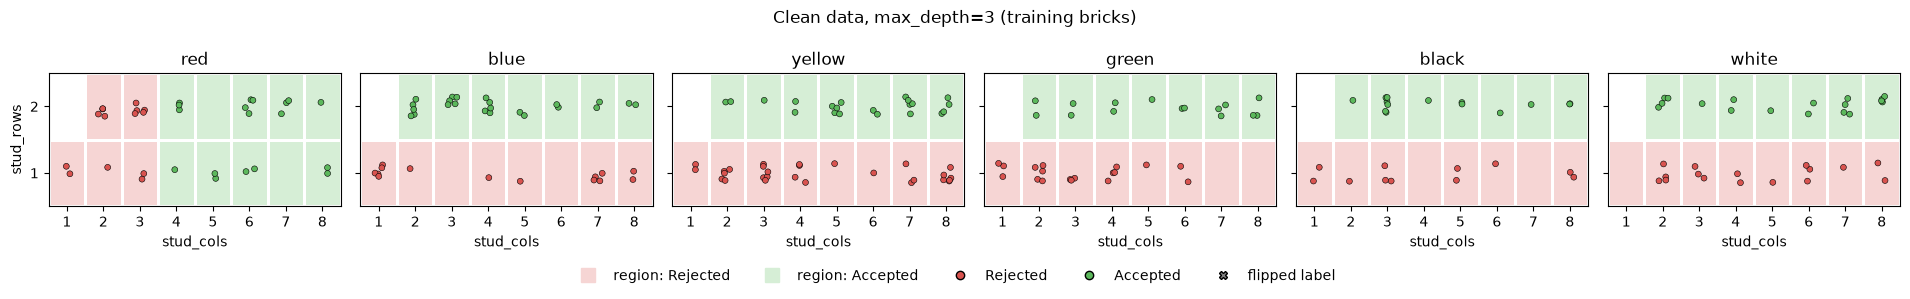

In [7]:
plots.plot_regions(tree, enc, train_df, title="Clean data, max_depth=3 (training bricks)")
plt.show()

### Tree diagram

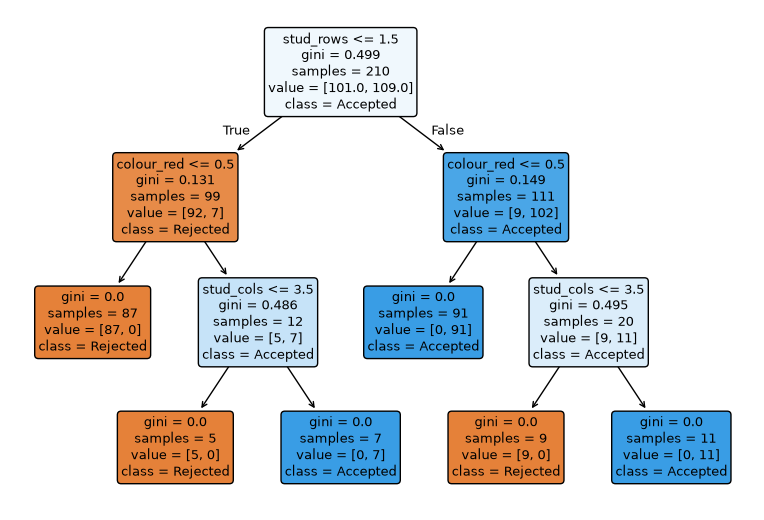

In [8]:
plots.plot_tree(tree, enc)
plt.show()

### Feature importances

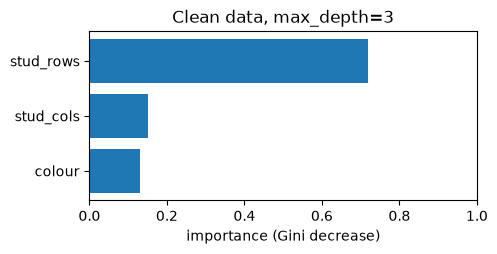

In [9]:
plots.plot_importances(tree, enc, title="Clean data, max_depth=3")
plt.show()

### Train/CV curve over depth
Scores come from 5-fold cross-validation on the training data only. The test set is not used to compare depths, to avoid lookahead bias.

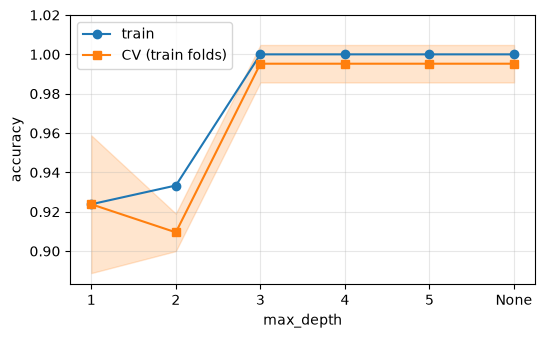

In [10]:
from sklearn.model_selection import cross_val_score

depths = [1, 2, 3, 4, 5, None]
train_acc, cv_mean, cv_std = [], [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv = cross_val_score(t, X_train, y_train, cv=5, scoring="accuracy")
    cv_mean.append(cv.mean())
    cv_std.append(cv.std())
    train_acc.append(t.fit(X_train, y_train).score(X_train, y_train))

plots.plot_curves(depths, train_acc, cv_scores=cv_mean, cv_std=cv_std, xlabel="max_depth")
plt.show()